In [13]:
import networkx as nx
import matplotlib.pyplot as plt

In [14]:
g = nx.read_graphml("graphs/wait_for_graph.graphml")

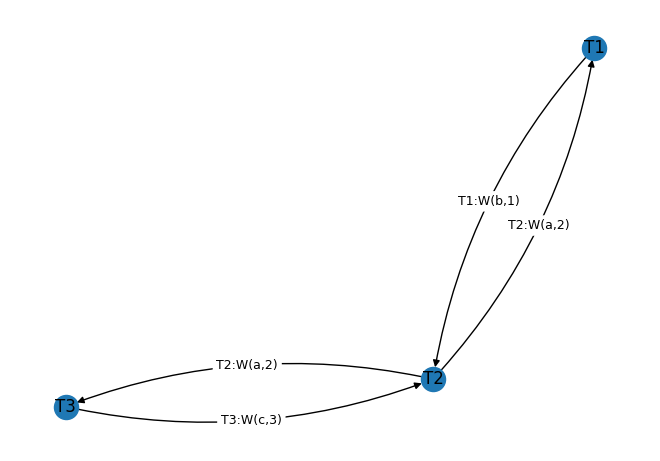

In [15]:
rad = 0.15   # Curvature of the edges, so that T1->T2 and T2->T1 do not overlap
pos = nx.spring_layout(g, seed=0)   # Fixed seed: the same layout on every run
nx.draw(g, pos, with_labels=True, connectionstyle=f'arc3, rad={rad}')
plt.gca().set_aspect('equal')   # Keeps the label positions below on the curves

# Show each edge's transaction_op attribute at the middle of that edge's own
# curve, so the two directions between a pair of transactions stay apart
for u, v, op in g.edges(data='transaction_op'):
    (x1, y1), (x2, y2) = pos[u], pos[v]
    plt.text((x1 + x2)/2 + rad*(y2 - y1)/2, (y1 + y2)/2 - rad*(x2 - x1)/2, op,
             ha='center', va='center', fontsize=9,
             bbox=dict(boxstyle='round', fc='white', ec='none'))